In [1]:

from google.colab import files

uploaded = files.upload()


Saving DathEon_Task1_Superstore_EDA.xlsx to DathEon_Task1_Superstore_EDA.xlsx


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

print("Dataset successfully loaded!")
print("Dataset Shape:", df.shape)

df.head()


Dataset successfully loaded!
Dataset Shape: (10800, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Column1,Column2,Column3
0,1,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,NaN,NaN,NaN
1,2,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,NaN,NaN,NaN
2,3,CA-2017-138688,2017-12-06 00:00:00,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,NaN,NaN,NaN
3,4,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,NaN,NaN,NaN
4,5,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,NaN,NaN,NaN


In [3]:

# Check all sheets in the uploaded Excel workbook

excel_file = pd.ExcelFile(file_name)

print("Available Sheets:")
print(excel_file.sheet_names)

# Check columns in the currently loaded sheet

print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information

print("\nDataset Information:")
df.info()


Available Sheets:
['Raw_Data', 'Cleaned_Data', 'State_Pivot', 'Segment_Category_Pivot', 'Pivot_Analysis', 'Region_Pivot', 'Segment_Pivot', 'Subcategory_Pivot', 'Monthly_Pivot', 'Shipping_Pivot', 'Data_Quality', 'EDA_Analysis', 'Subcategory_Analysis', 'Monthly_Analysis', 'Product_Analysis', 'Dashboard']

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Column1', 'Column2', 'Column3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   o

In [4]:

print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())


Missing Values in Each Column:
Row ID               0
Order ID             0
Order Date         806
Ship Date          806
Ship Mode          806
Customer ID        806
Customer Name      806
Segment            806
Country            806
City               806
State              806
Postal Code        817
Region             806
Product ID         806
Category           806
Sub-Category       806
Product Name       806
Sales              806
Quantity           806
Discount           806
Profit             806
Column1          10800
Column2          10800
Column3          10800
dtype: int64

Duplicate Rows:
504

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Column1,Column2,Column3
0,1,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,NaN,NaN,NaN
1,2,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,NaN,NaN,NaN
2,3,CA-2017-138688,2017-12-06 00:00:00,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,NaN,NaN,NaN
3,4,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,NaN,NaN,NaN
4,5,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,NaN,NaN,NaN


In [5]:

# Load only the original Raw_Data sheet
raw = pd.read_excel(file_name, sheet_name="Raw_Data")

# Remove completely empty extra columns for inspection only
raw_check = raw.drop(
    columns=["Column1", "Column2", "Column3"],
    errors="ignore"
)

print("Raw Data Shape:", raw.shape)

print("\nRows with missing Order Date:",
      raw_check["Order Date"].isna().sum())

print("\nRows with missing Row ID:",
      raw_check["Row ID"].isna().sum())

print("\nDuplicate complete records:",
      raw_check.duplicated().sum())

print("\nDuplicate Row IDs:",
      raw_check["Row ID"].duplicated().sum())

print("\nLast 10 rows:")
display(raw_check.tail(10))

print("\nSample rows with missing Order Date:")
display(raw_check[raw_check["Order Date"].isna()].head(10))


Raw Data Shape: (10800, 24)

Rows with missing Order Date: 806

Rows with missing Row ID: 0

Duplicate complete records: 504

Duplicate Row IDs: 799

Last 10 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10790,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10791,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Sample rows with missing Order Date:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

# Find repeated Row IDs
duplicate_ids = raw_check[
    raw_check["Row ID"].duplicated(keep=False)
].sort_values("Row ID")

print("Total rows having repeated Row IDs:",
      len(duplicate_ids))

print("\nFirst 20 repeated Row ID records:")
display(duplicate_ids.head(20))

# Check rows with missing Order Date
missing_date_rows = raw_check[
    raw_check["Order Date"].isna()
]

print("\nRows with missing Order Date:")
display(missing_date_rows.head(10))

# Count unique Row IDs
print("\nUnique Row IDs:",
      raw_check["Row ID"].nunique())


Total rows having repeated Row IDs: 800

First 20 repeated Row ID records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10527,Yes,CA-2018-130631,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10528,Yes,CA-2018-131492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10529,Yes,CA-2018-131492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10530,Yes,CA-2018-131492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10531,Yes,CA-2018-131492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10532,Yes,CA-2018-131618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10533,Yes,CA-2018-131618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10534,Yes,CA-2018-131618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10535,Yes,CA-2018-131807,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Rows with missing Order Date:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique Row IDs: 10001


In [7]:

# Check how many genuine sales records exist

print("Total rows:", len(raw_check))

print("Rows with valid Order Date:",
      raw_check["Order Date"].notna().sum())

print("Rows with valid Sales:",
      raw_check["Sales"].notna().sum())

print("Rows with valid Product ID:",
      raw_check["Product ID"].notna().sum())

# Count rows containing actual sales information
valid_sales = raw_check[
    raw_check["Order Date"].notna() &
    raw_check["Order ID"].notna() &
    raw_check["Product ID"].notna() &
    raw_check["Sales"].notna()
].copy()

print("\nValid Sales Records:", len(valid_sales))

print("\nMissing values in valid sales records:")
print(valid_sales.isnull().sum())


Total rows: 10800
Rows with valid Order Date: 9994
Rows with valid Sales: 9994
Rows with valid Product ID: 9994

Valid Sales Records: 9994

Missing values in valid sales records:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [8]:

print("Last 15 rows of the original sheet:")
display(raw_check.tail(15))

print("\nFirst 5 valid sales records:")
display(valid_sales.head())


Last 15 rows of the original sheet:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10785,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10786,Yes,US-2018-123834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10787,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10788,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10789,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10790,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10791,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



First 5 valid sales records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,2017-12-06 00:00:00,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [9]:

# Create a separate clean dataset
cleaned_df = valid_sales.copy()

# Remove unnecessary extra columns, if present
cleaned_df = cleaned_df.drop(
    columns=["Column1", "Column2", "Column3"],
    errors="ignore"
)

# Reset row numbering
cleaned_df = cleaned_df.reset_index(drop=True)

# Convert Order Date and Ship Date into datetime
cleaned_df["Order Date"] = pd.to_datetime(
    cleaned_df["Order Date"], errors="coerce"
)

cleaned_df["Ship Date"] = pd.to_datetime(
    cleaned_df["Ship Date"], errors="coerce"
)

# Extract Year and Month
cleaned_df["Order Year"] = cleaned_df["Order Date"].dt.year
cleaned_df["Order Month"] = cleaned_df["Order Date"].dt.month
cleaned_df["Year-Month"] = cleaned_df["Order Date"].dt.to_period("M").astype(str)

# Handle missing Postal Codes without deleting records
cleaned_df["Postal Code"] = cleaned_df["Postal Code"].fillna("Unknown")

print("Data cleaning completed!")

print("Cleaned Dataset Shape:", cleaned_df.shape)

print("\nMissing Values:")
print(cleaned_df.isnull().sum())

display(cleaned_df.head())


Data cleaning completed!
Cleaned Dataset Shape: (9994, 24)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Order Year       0
Order Month      0
Year-Month       0
dtype: int64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Year-Month
0,1,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017,8,2017-08
1,2,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017,8,2017-08
2,3,CA-2017-138688,2017-12-06,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017,12,2017-12
3,4,US-2016-108966,2016-11-10,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016,11,2016-11
4,5,US-2016-108966,2016-11-10,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016,11,2016-11


In [10]:

# Check exact duplicate transactions

print("Exact duplicate rows:",
      cleaned_df.duplicated().sum())

print("Duplicate Row IDs:",
      cleaned_df["Row ID"].duplicated().sum())

print("Unique Order IDs:",
      cleaned_df["Order ID"].nunique())

print("Unique Customers:",
      cleaned_df["Customer ID"].nunique())

print("Unique Products:",
      cleaned_df["Product ID"].nunique())


Exact duplicate rows: 0
Duplicate Row IDs: 0
Unique Order IDs: 5009
Unique Customers: 793
Unique Products: 1862


In [11]:

# Calculate customer-wise purchase volume

customer_analysis = (
    cleaned_df.groupby("Customer ID")
    .agg(
        Customer_Name=("Customer Name", "first"),
        Total_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

print("Total Unique Customers:",
      customer_analysis.shape[0])

print("\nTop 10 Customers by Sales:")

display(
    customer_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)


Total Unique Customers: 793

Top 10 Customers by Sales:


,Customer ID,Customer_Name,Total_Orders,Total_Sales,Total_Quantity,Total_Profit
700,SM-20320,Sean Miller,5,25043.050,50.0,-1980.7393
741,TC-20980,Tamara Chand,5,19052.218,42.0,8981.3239
621,RB-19360,Raymond Buch,6,15117.339,71.0,6976.0959
730,TA-21385,Tom Ashbrook,4,14595.620,36.0,4703.7883
6,AB-10105,Adrian Barton,10,14473.571,73.0,5444.8055
434,KL-16645,Ken Lonsdale,12,14175.229,113.0,806.8550
669,SC-20095,Sanjit Chand,9,14142.334,87.0,5757.4119
327,HL-15040,Hunter Lopez,6,12873.298,50.0,5622.4292
683,SE-20110,Sanjit Engle,11,12209.438,78.0,2650.6769
131,CC-12370,Christopher Conant,5,12129.072,34.0,2177.0493


Monthly Sales Analysis:


,Year-Month,Total_Sales,Total_Profit,Total_Quantity
0,2015-01,28953.7060,4549.4546,508.0
1,2015-02,12743.1080,2654.5569,319.0
2,2015-03,54801.9060,92.6990,611.0
3,2015-04,24710.0160,4601.0714,470.0
4,2015-05,29639.8340,3912.2499,551.0
5,2015-06,29287.0306,4499.7446,497.0
6,2015-07,35341.2460,-1783.5425,590.0
7,2015-08,37854.5475,2081.2676,604.0
8,2015-09,66110.2238,10232.2626,903.0
9,2015-10,34561.9470,4075.1499,555.0


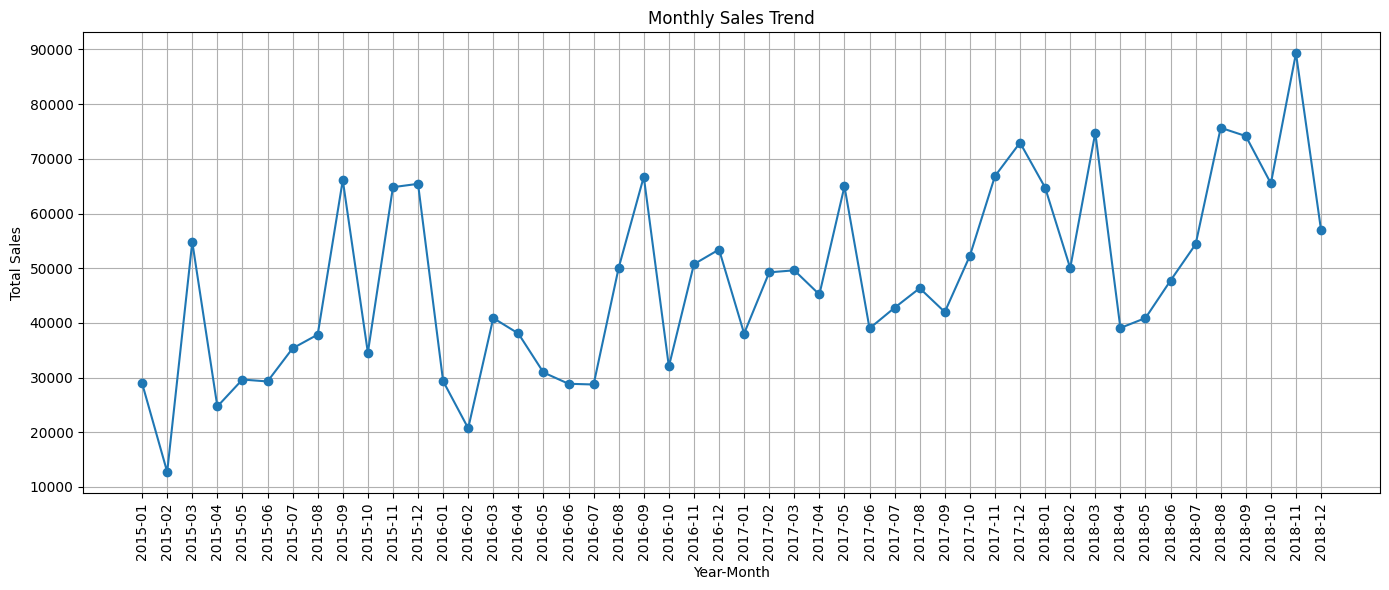

In [12]:

# Monthly sales and profit analysis

monthly_sales = (
    cleaned_df.groupby("Year-Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

print("Monthly Sales Analysis:")
display(monthly_sales.head(10))

# Monthly Sales Trend Chart

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

category_analysis = (
    cleaned_df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

display(category_analysis)


,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,741999.7953,18451.2728,8028.0
1,Office Supplies,719047.0320,122490.8008,22906.0
2,Technology,836154.0330,145454.9481,6939.0


,Year-Month,Total_Sales,Total_Profit,Total_Quantity
0,2015-01,28953.7060,4549.4546,508.0
1,2015-02,12743.1080,2654.5569,319.0
2,2015-03,54801.9060,92.6990,611.0
3,2015-04,24710.0160,4601.0714,470.0
4,2015-05,29639.8340,3912.2499,551.0
5,2015-06,29287.0306,4499.7446,497.0
6,2015-07,35341.2460,-1783.5425,590.0
7,2015-08,37854.5475,2081.2676,604.0
8,2015-09,66110.2238,10232.2626,903.0
9,2015-10,34561.9470,4075.1499,555.0


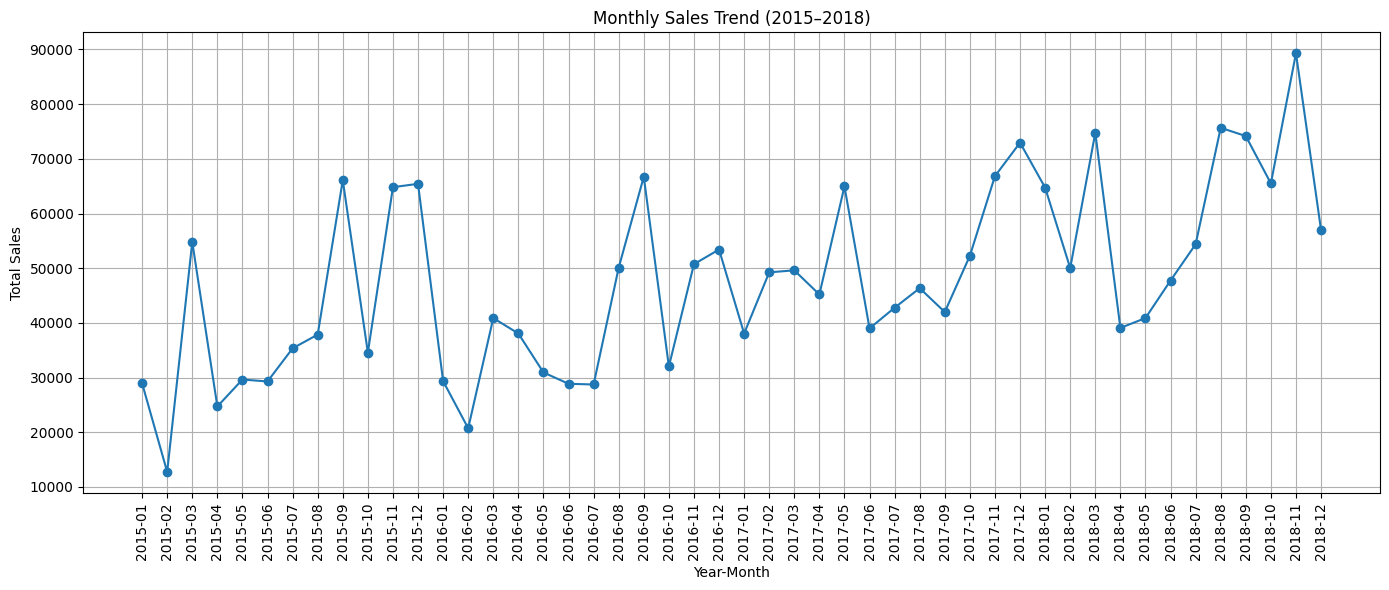

In [14]:
monthly_sales = (
    cleaned_df.groupby("Year-Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

display(monthly_sales.head(10))

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2015–2018)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Highest and lowest sales months
best_sales_month = monthly_sales.loc[monthly_sales["Total_Sales"].idxmax()]
worst_sales_month = monthly_sales.loc[monthly_sales["Total_Sales"].idxmin()]

# Highest and lowest profit months
best_profit_month = monthly_sales.loc[monthly_sales["Total_Profit"].idxmax()]
worst_profit_month = monthly_sales.loc[monthly_sales["Total_Profit"].idxmin()]

print("Highest Sales Month:")
print(best_sales_month)

print("\nLowest Sales Month:")
print(worst_sales_month)

print("\nHighest Profit Month:")
print(best_profit_month)

print("\nLowest Profit Month:")
print(worst_profit_month)

Highest Sales Month:
Year-Month           2018-11
Total_Sales         89306.24
Total_Profit      11141.8845
Total_Quantity        1509.0
Name: 46, dtype: object

Lowest Sales Month:
Year-Month          2015-02
Total_Sales       12743.108
Total_Profit      2654.5569
Total_Quantity        319.0
Name: 1, dtype: object

Highest Profit Month:
Year-Month           2018-03
Total_Sales       74774.0838
Total_Profit      18127.8605
Total_Quantity        1138.0
Name: 38, dtype: object

Lowest Profit Month:
Year-Month           2018-04
Total_Sales       39072.0016
Total_Profit      -5890.0374
Total_Quantity         803.0
Name: 39, dtype: object


In [16]:
category_analysis = (
    cleaned_df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

display(category_analysis)

,Category,Total_Sales,Total_Profit,Total_Quantity,Average_Discount
0,Furniture,741999.7953,18451.2728,8028.0,0.173923
1,Office Supplies,719047.0320,122490.8008,22906.0,0.157285
2,Technology,836154.0330,145454.9481,6939.0,0.132323


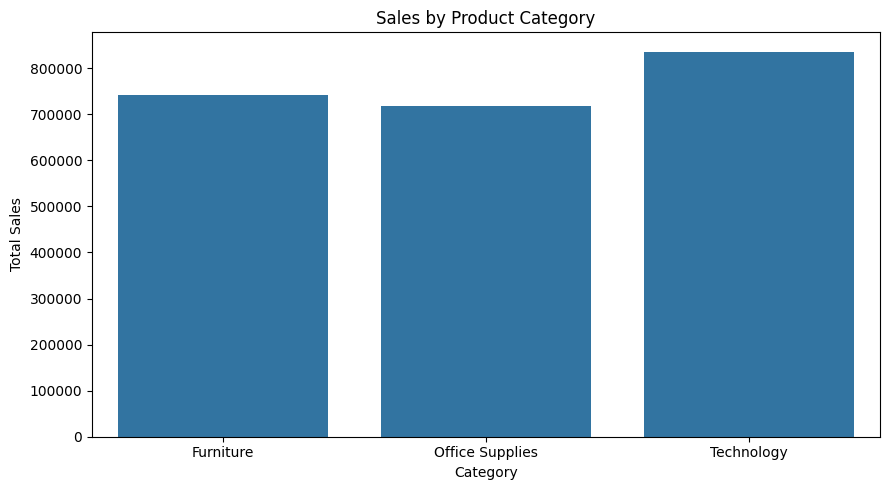

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales"
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [18]:
region_analysis = (
    cleaned_df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

display(region_analysis)

,Region,Total_Sales,Total_Profit,Total_Quantity,Average_Discount
0,Central,501239.8908,39706.3625,8780.0,0.240353
1,East,678781.2400,91522.7800,10618.0,0.145365
2,South,391721.9050,46749.4303,6209.0,0.147253
3,West,725457.8245,108418.4489,12266.0,0.109335


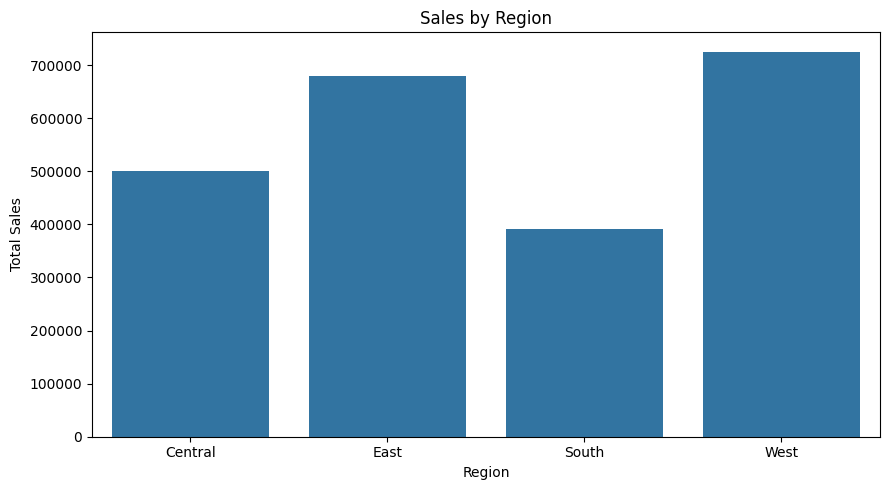

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [20]:
segment_analysis = (
    cleaned_df.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

display(segment_analysis)

,Segment,Total_Sales,Total_Profit,Total_Quantity,Average_Discount
0,Consumer,1.161401e+06,134119.2092,19521.0,0.158141
1,Corporate,7.061464e+05,91979.1340,11608.0,0.158228
2,Home Office,4.296531e+05,60298.6785,6744.0,0.147128


In [21]:
# Calculate correlation between Discount and Profit

discount_profit_corr = cleaned_df["Discount"].corr(cleaned_df["Profit"])

print("Correlation between Discount and Profit:", discount_profit_corr)

Correlation between Discount and Profit: -0.21948745637176803


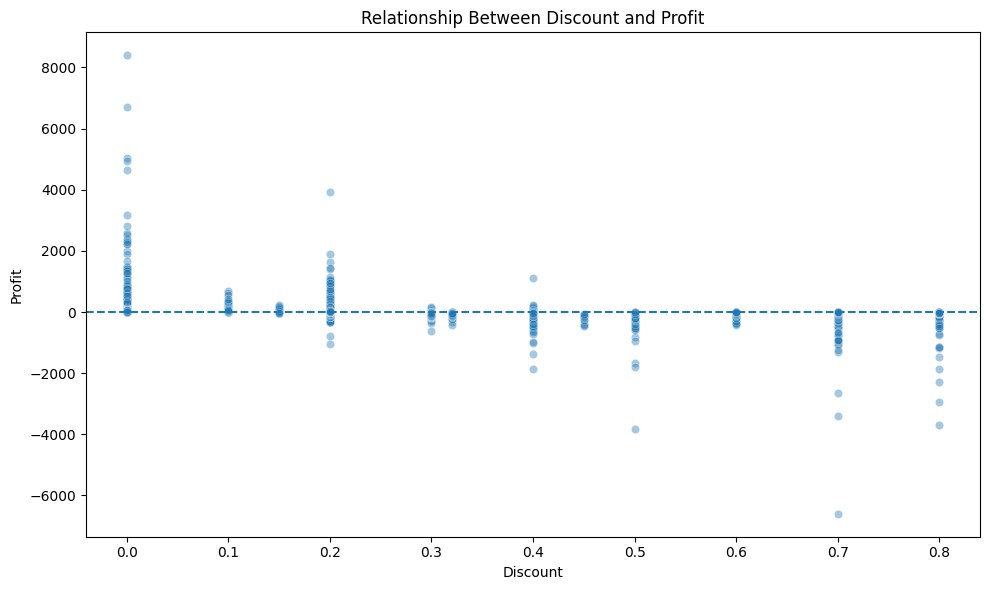

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cleaned_df,
    x="Discount",
    y="Profit",
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [23]:
product_analysis = (
    cleaned_df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Top 10 products by sales
top_sales_products = product_analysis.sort_values(
    "Total_Sales", ascending=False
).head(10)

# Top 10 products by profit
top_profit_products = product_analysis.sort_values(
    "Total_Profit", ascending=False
).head(10)

# Bottom 10 products by profit
bottom_profit_products = product_analysis.sort_values(
    "Total_Profit", ascending=True
).head(10)

print("TOP 10 PRODUCTS BY SALES")
display(top_sales_products)

print("TOP 10 PRODUCTS BY PROFIT")
display(top_profit_products)

print("BOTTOM 10 PRODUCTS BY PROFIT")
display(bottom_profit_products)

TOP 10 PRODUCTS BY SALES


,Product Name,Total_Sales,Total_Profit,Total_Quantity
404,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20.0
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03,31.0
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03,6.0
786,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39.0
686,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37.0
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48.0
805,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38.0
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03,12.0
683,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27.0
813,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02,11.0


TOP 10 PRODUCTS BY PROFIT


,Product Name,Total_Sales,Total_Profit,Total_Quantity
404,Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20.0
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7753.0390,31.0
805,Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38.0
400,Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19.0
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4094.9766,12.0
165,Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11.0
19,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11.0
1276,Plantronics Savi W720 Multi-Device Wireless He...,9367.290,3696.2820,24.0
895,Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13.0
1840,Zebra ZM400 Thermal Label Printer,6965.700,3343.5360,6.0


BOTTOM 10 PRODUCTS BY PROFIT


,Product Name,Total_Sales,Total_Profit,Total_Quantity
475,Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9.0
985,Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18.0
476,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4.0
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.640,-2876.1156,27.0
376,Bush Advantage Collection Racetrack Conference...,9544.725,-1934.3976,33.0
683,GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27.0
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1811.0784,6.0
1043,Martin Yale Chadless Opener Electric Letter Op...,16656.200,-1299.1836,22.0
285,Balt Solid Wood Round Tables,6518.754,-1201.0581,19.0
364,BoxOffice By Design Rectangular and Half-Moon ...,1706.250,-1148.4375,15.0



# Task 1: Exploratory Data Analysis – Business Findings

## 1. Technology is the strongest product category
Technology generated the highest sales of 836,154.03 and the highest profit of 145,454.95. Furniture generated 741,999.80 in sales but only 18,451.27 in profit, indicating comparatively low profitability.

## 2. West is the best-performing region
The West region recorded the highest sales of 725,457.82 and profit of 108,418.45. Central had the highest average discount of 24.04% but generated only 39,706.36 in profit.

## 3. Consumer is the leading customer segment
The Consumer segment generated the highest sales of 1,161,401.35 and profit of 134,119.21. It represents the largest customer segment in terms of sales contribution.

## 4. Discounts have a weak negative relationship with profit
The correlation between Discount and Profit was -0.2195, indicating a weak negative relationship. Higher discounts tend to be associated with lower profits, although other factors also influence profitability.

## 5. Product sales and profitability are not always aligned
Canon imageCLASS 2200 Advanced Copier was the top product by both sales (61,599.82) and profit (25,199.93). However, Cisco TelePresence System EX90 generated 22,638.48 in sales but recorded a loss of 1,811.08. The Cubify CubeX 3D Printer Double Head Print recorded the largest product-level loss of 8,879.97.

## Conclusion
The analysis indicates that product category, geographical region, customer segment, discount strategy and individual product profitability are important factors affecting overall business performance. The company should focus on profitable products and regions while reviewing discounting and loss-making products.
